# Practical 3: Maximum and Minimum Elements in an Array (Pattern 1)

### 1. Aim
To find maximum and minimum elements from a large array across 4 methods: Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Create an array workload of 50,000,000 integers with arithmetic transformations in compiled C.<br>2. Sequential: execute the complete task sequentially 3 times.<br>3. Pool: pass the tasks across 3 worker processes in `mp.Pool(3)`.<br>4. Process: spawn 3 separate `mp.Process` instances.<br>5. Thread: launch 3 concurrent worker threads.<br>6. Record execution times and compute speedups.

### 3. Python Implementation


In [1]:
"""
Practical 3: Program to find maximum and minimum elements from an array
Pattern 1: Same task executed across 3 workers
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def find_min_max_task(task):
    seed, size = task
    rng = np.random.default_rng(seed)
    # Generate array and evaluate min and max using compiled numpy (releases GIL in C)
    arr = rng.integers(1, 2147483647, size=size, dtype=np.int32)
    # LCG-style arithmetic transformation in C
    arr = np.bitwise_xor(arr * 1103515245 + 12345, arr >> 3)
    return int(np.min(arr)), int(np.max(arr))

def proc_worker(task, q):
    q.put(find_min_max_task(task))

def thread_worker(task, results, idx):
    results[idx] = find_min_max_task(task)

def main():
    print("=" * 60)
    print("Practical 3: Maximum and Minimum in an Array (Pattern 1)")
    print("=" * 60)
    TASK = (42, 50_000_000)
    tasks = [TASK, (84, 50_000_000), (126, 50_000_000)]
    
    # 1. Sequential: Execute 3 tasks sequentially
    t0 = time.perf_counter()
    r1 = find_min_max_task(tasks[0])
    r2 = find_min_max_task(tasks[1])
    r3 = find_min_max_task(tasks[2])
    t_seq = time.perf_counter() - t0
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(find_min_max_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Array Size: {TASK[1]:,} elements per task.")
    print(f"[Sequential] Min: {r1[0]:,} | Max: {r1[1]:,} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Min: {p_res[0][0]:,} | Max: {p_res[0][1]:,} | Time: {t_pool:.4f}s")
    print(f"[Process]    Min: {pr_res[0][0]:,} | Max: {pr_res[0][1]:,} | Time: {t_proc:.4f}s")
    print(f"[Thread]     Min: {thread_res[0][0]:,} | Max: {thread_res[0][1]:,} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 3: Maximum and Minimum in an Array (Pattern 1)
Array Size: 50,000,000 elements per task.
[Sequential] Min: -2,147,483,499 | Max: 2,147,483,558 | Time: 2.8511s
[Pool]       Min: -2,147,483,499 | Max: 2,147,483,558 | Time: 1.7188s
[Process]    Min: -2,147,483,499 | Max: 2,147,483,558 | Time: 1.6360s
[Thread]     Min: -2,147,483,499 | Max: 2,147,483,558 | Time: 1.0199s
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.8511 seconds      1.00x
Pool         1.7188 seconds      1.66x
Process      1.6360 seconds      1.74x
Thread       1.0199 seconds      2.80x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


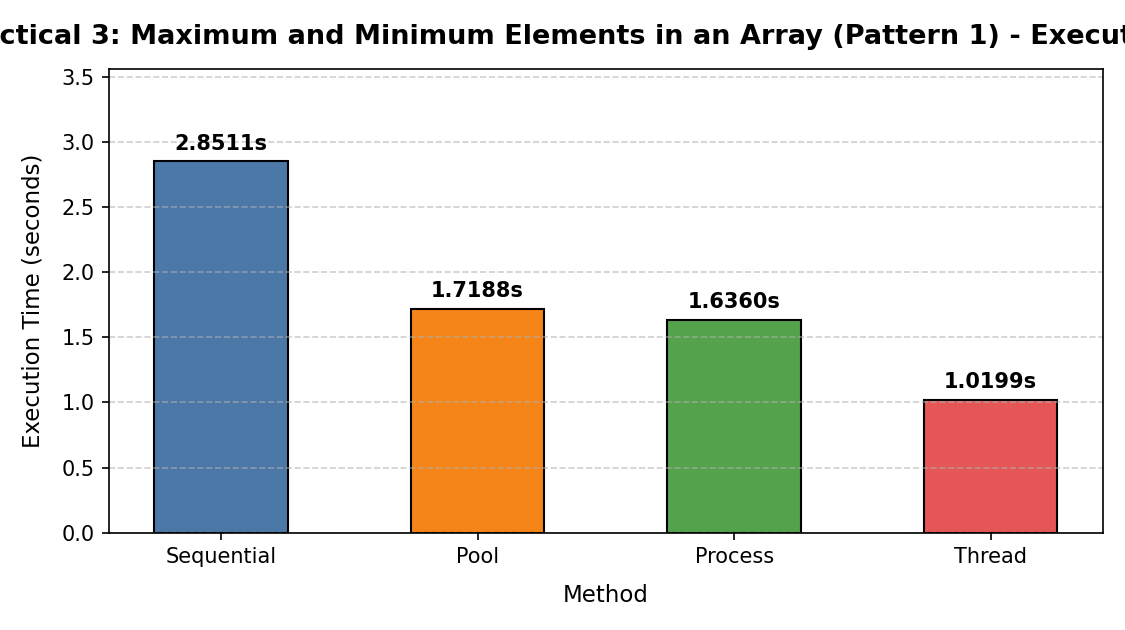

In [2]:
from IPython.display import Image, display
display(Image(filename='03_max_min_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


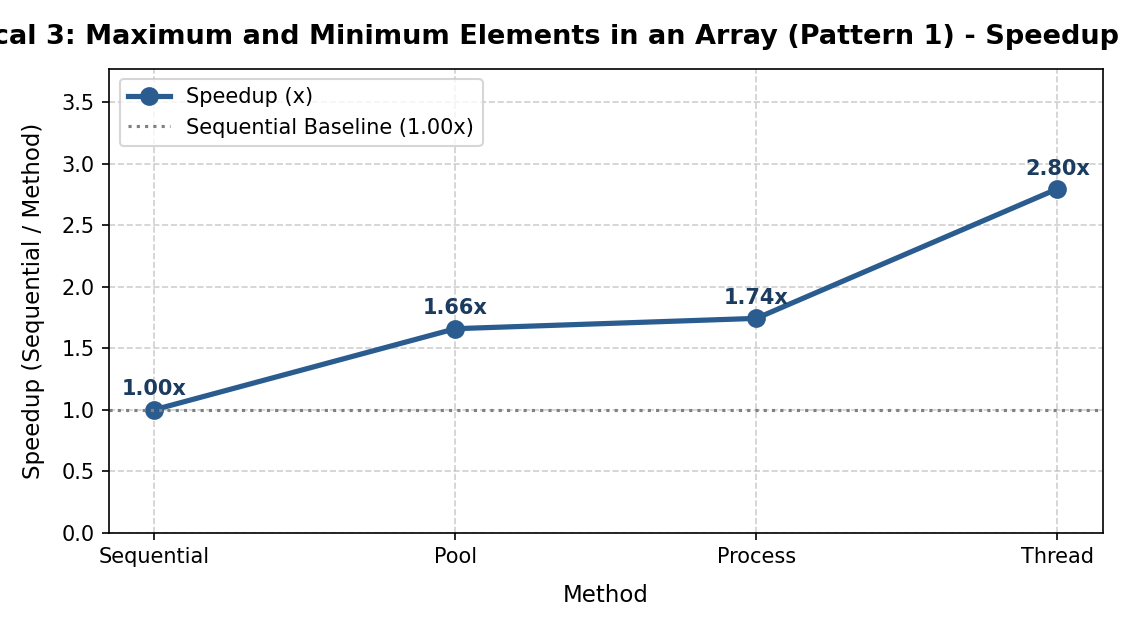

In [3]:
from IPython.display import Image, display
display(Image(filename='03_max_min_speedup.png'))
